In [4]:
import pandas as pd
import numpy as np
from sqlalchemy import create_engine
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
from sklearn.metrics import mean_absolute_percentage_error, r2_score

import sys
from pathlib import Path

# Connect to PostgreSQL database using settings
PROJECT_ROOT = Path().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from config.settings import DATABASE_URL

engine = create_engine(DATABASE_URL)
df_japan = pd.read_sql("SELECT * FROM clean_japan_listings;", engine)
print(f"Loaded {len(df_japan)} records from clean_japan_listings.")
df_japan.head(3)

Loaded 599 records from clean_japan_listings.


,id,listing_url,source_site,make,model,year,mileage_km,engine_cc,fuel_type,transmission,fob_price_usd
0,102,https://www.beforward.jp/honda/freed/cd774314/...,BEFORWARD,HONDA,FREED,2019,41000,1500,PETROL,AUTOMATIC,14320.0
1,103,https://www.beforward.jp/toyota/corolla-cross/...,BEFORWARD,TOYOTA,COROLLA,2022,15000,1800,HYBRID(PETROL),AUTOMATIC,23500.0
2,108,https://www.beforward.jp/bmw/mini/ce799157/id/...,BEFORWARD,BMW,MINI,2024,3000,1750,ELECTRIC,AUTOMATIC,25350.0


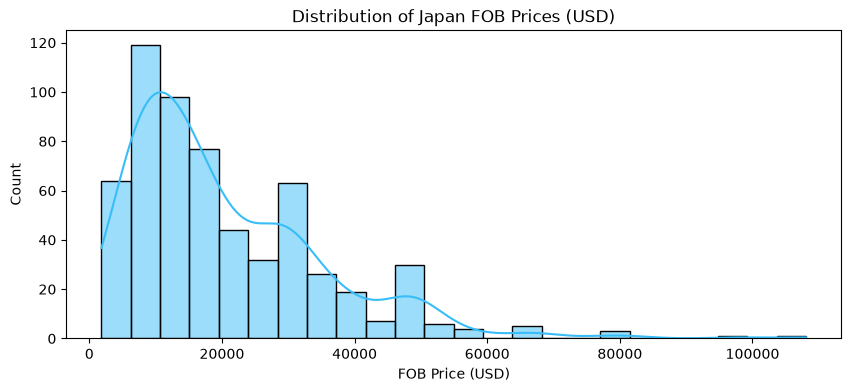

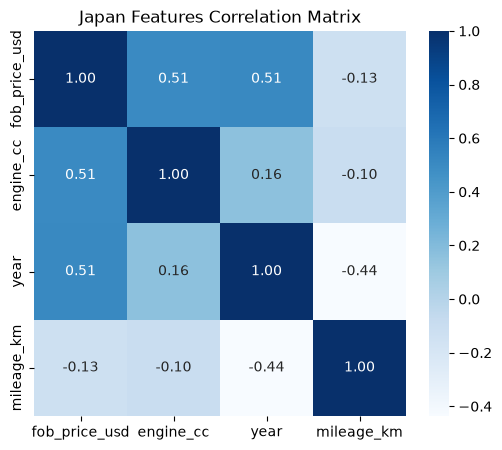

In [5]:
# Distribution of Japan FOB Prices (USD)
plt.figure(figsize=(10, 4))
sns.histplot(pd.to_numeric(df_japan['fob_price_usd'], errors='coerce'), kde=True, color='#38bdf8')
plt.title("Distribution of Japan FOB Prices (USD)")
plt.xlabel("FOB Price (USD)")
plt.show()

# Correlation matrix of numerical features
num_cols = ['fob_price_usd', 'engine_cc', 'year', 'mileage_km']
df_num = df_japan[num_cols].apply(pd.to_numeric, errors='coerce')

plt.figure(figsize=(6, 5))
sns.heatmap(df_num.corr(), annot=True, cmap='Blues', fmt=".2f")
plt.title("Japan Features Correlation Matrix")
plt.show()

In [6]:
jp_features = ['engine_cc', 'year', 'mileage_km']
jp_cats = ['make', 'model', 'fuel_type', 'transmission', 'source_site']

for col in jp_features:
    df_japan[col] = pd.to_numeric(df_japan[col], errors='coerce').fillna(df_japan[col].median())

X_raw = df_japan[jp_cats + jp_features].fillna('UNKNOWN')
X = pd.get_dummies(X_raw, drop_first=True)
y = pd.to_numeric(df_japan['fob_price_usd'], errors='coerce').fillna(df_japan['fob_price_usd'].median())

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training set shape: {X_train.shape}, Testing set shape: {X_test.shape}")

Training set shape: (479, 159), Testing set shape: (120, 159)


In [7]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=150, max_depth=12, random_state=42),
    "XGBoost": xgb.XGBRegressor(n_estimators=150, learning_rate=0.05, max_depth=5, random_state=42)
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    mape = mean_absolute_percentage_error(y_test, preds) * 100
    r2 = r2_score(y_test, preds)
    results[name] = {"MAPE": mape, "R2": r2}
    print(f"[{name}] ➔ Test MAPE: {mape:.2f}% | Test R²: {r2:.4f}")

[Linear Regression] ➔ Test MAPE: 44.04% | Test R²: 0.4747
[Ridge Regression] ➔ Test MAPE: 38.82% | Test R²: 0.6045
[Random Forest] ➔ Test MAPE: 24.12% | Test R²: 0.7061
[XGBoost] ➔ Test MAPE: 25.89% | Test R²: 0.6753


In [8]:
import joblib
from pathlib import Path

# Find best model based on R2 score or MAPE
best_model_name = min(results, key=lambda k: results[k]['MAPE'])
best_model = models[best_model_name]

# Save model artifact
Path("models").mkdir(exist_ok=True)
joblib.dump(best_model, "models/best_japan_model.pkl")
print(f"✨ Successfully saved {best_model_name} as the best Japan model!")

✨ Successfully saved Random Forest as the best Japan model!
